# Redundancy (rank correlation) and in-sample IC

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

chars = char_names()
df = rank_normalise(is_universe(), chars + ["ret"])

def avg_corr(frame, cols, ret=None):
    """Average monthly pairwise-complete correlation of rank-normalised columns, plus monthly ICs vs ret."""
    P = len(cols); S = np.zeros((P, P)); N = np.zeros((P, P)); ics = []
    for _, g in frame.group_by("DATE", maintain_order=True):
        X = g.select(cols).to_numpy(); M = ~np.isnan(X); Z = np.where(M, X, 0.0); Mf = M.astype(float)
        n = Mf.T @ Mf; sx = Z.T @ Mf; sxx = (Z ** 2).T @ Mf; sxy = Z.T @ Z
        with np.errstate(invalid="ignore", divide="ignore"):
            var = sxx / n - (sx / n) ** 2
            C = (sxy / n - (sx / n) * (sx.T / n)) / np.sqrt(var * var.T)
        ok = (n > 100) & np.isfinite(C); S += np.where(ok, C, 0); N += ok
        if ret is not None:
            r = g[ret].to_numpy()
            ics.append([np.corrcoef(X[M[:, k], k], r[M[:, k]])[0, 1] if M[:, k].sum() > 100 else np.nan for k in range(P)])
    C = S / N; np.fill_diagonal(C, 1.0)
    return C, np.array(ics)

corr, ics = avg_corr(df, chars, ret="ret")
P = len(chars); iu = np.triu_indices(P, 1)

## Average monthly Spearman correlation (pairwise-complete)

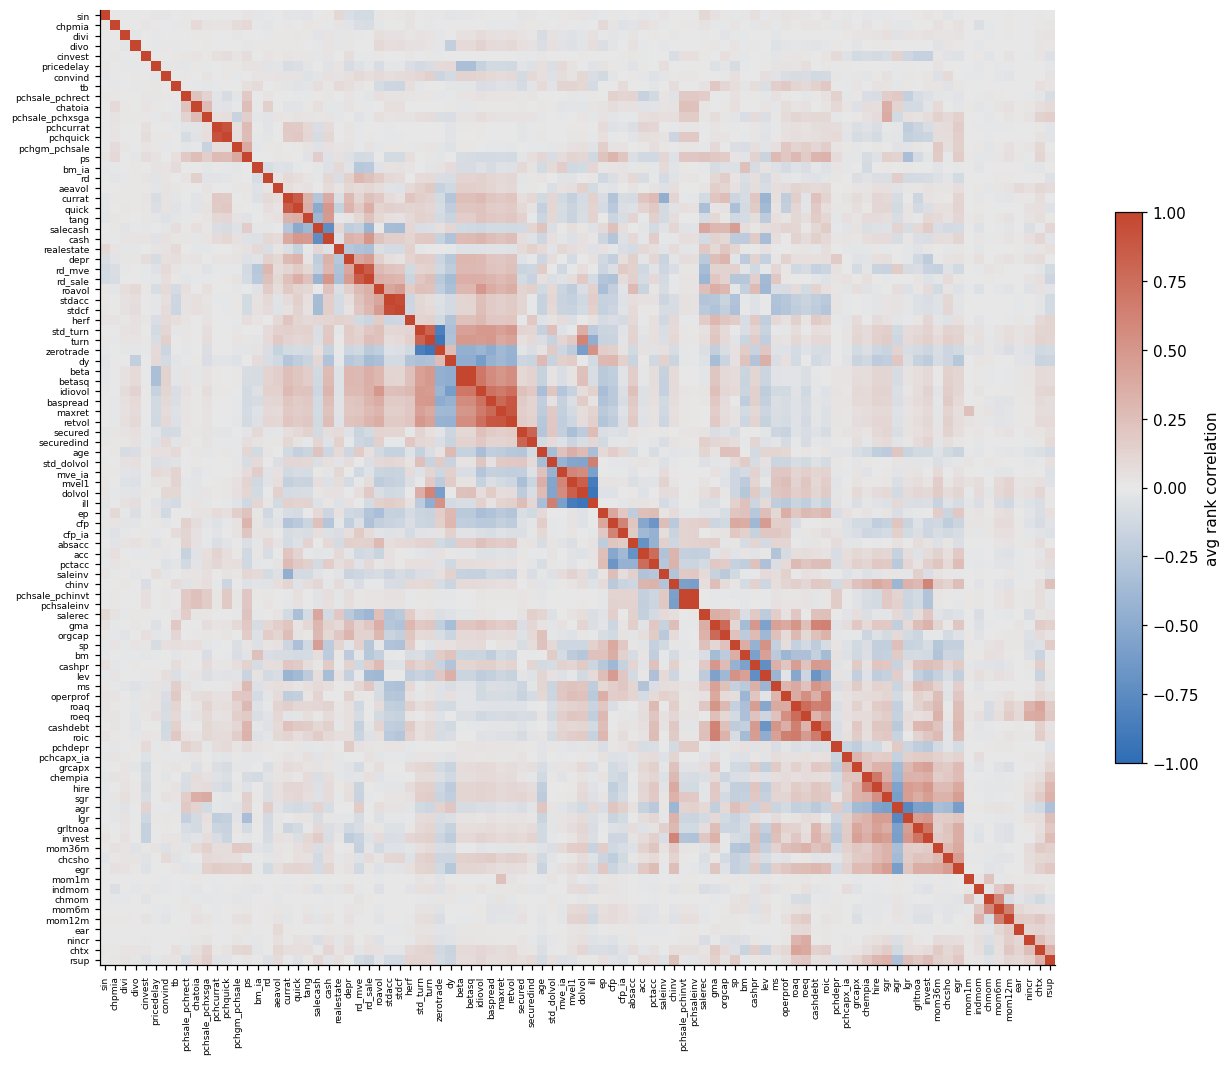

In [3]:
order = leaves_list(linkage(squareform(1 - np.abs(corr), checks=False), "average"))
fig, ax = plt.subplots(figsize=(14, 13))
im = ax.imshow(corr[np.ix_(order, order)], cmap=DIVERGING, vmin=-1, vmax=1)
names = [chars[i] for i in order]
ax.set_xticks(range(P), names, rotation=90, fontsize=6); ax.set_yticks(range(P), names, fontsize=6)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.5, label="avg rank correlation"); plt.show()

## Number of pairs above each |correlation| threshold

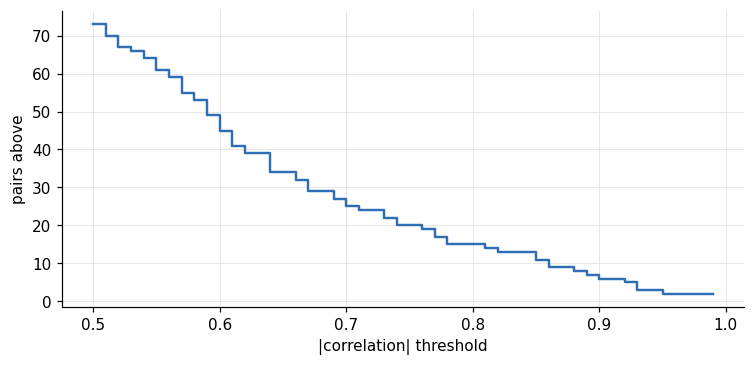

In [4]:
th = np.linspace(0.5, 0.99, 50)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(th, [(np.abs(corr[iu]) > t).sum() for t in th], where="post", color=BLUE, lw=1.6)
ax.set_xlabel("|correlation| threshold"); ax.set_ylabel("pairs above"); plt.show()

## In-sample IC t-stat: monthly rank correlation with the same-month return

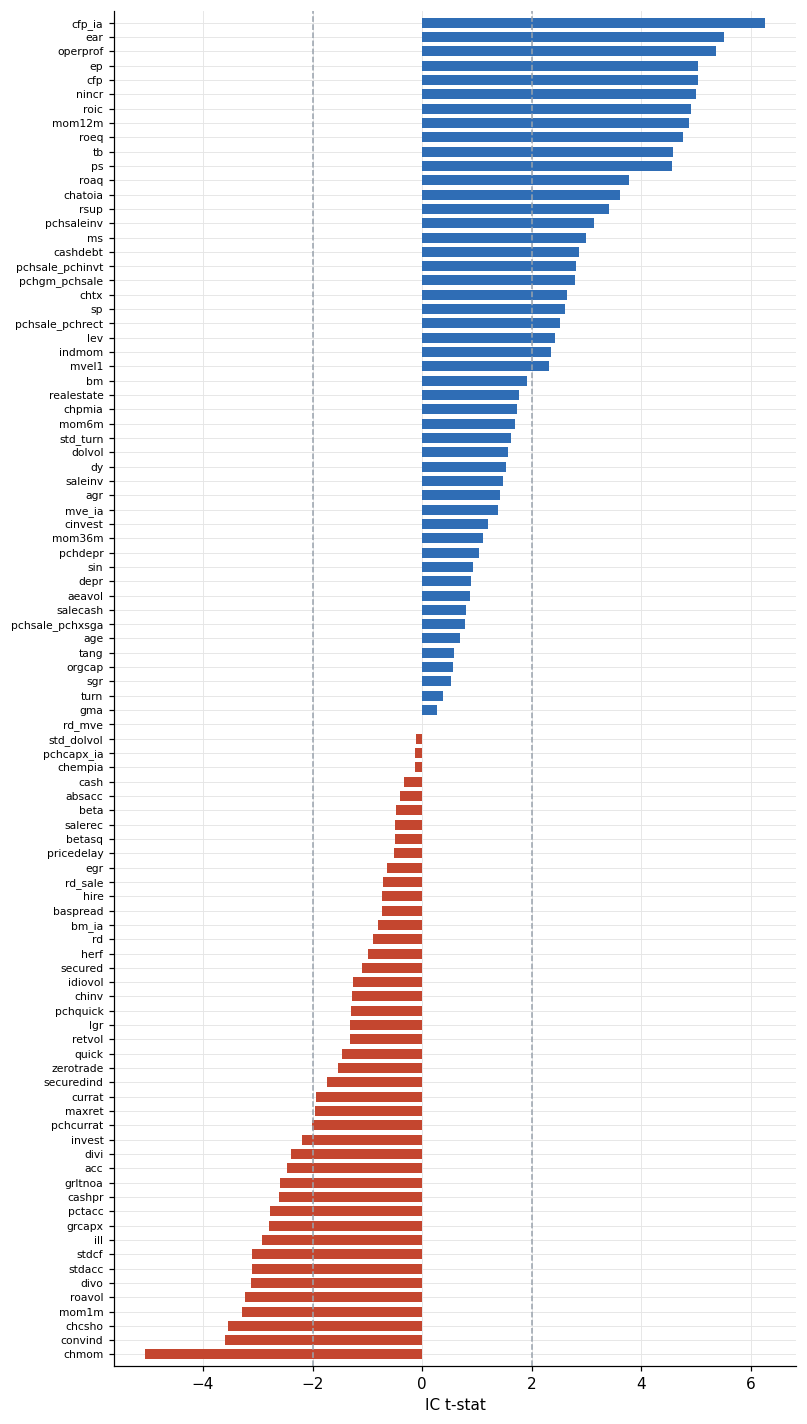

In [5]:
ic_mean = np.nanmean(ics, 0)
ic_t = ic_mean / (np.nanstd(ics, 0, ddof=1) / np.sqrt((~np.isnan(ics)).sum(0)))
ic = pl.DataFrame({"char": chars, "ic_mean": ic_mean, "ic_t": ic_t}).sort("ic_t")
fig, ax = plt.subplots(figsize=(8, 16))
ax.barh(ic["char"], ic["ic_t"], color=[BLUE if v > 0 else "#c4462f" for v in ic["ic_t"]], height=0.7)
for x in (-2, 2):
    ax.axvline(x, color=GREY, lw=1, ls="--")
ax.set_xlabel("IC t-stat"); ax.tick_params(axis="y", labelsize=7); ax.margins(y=0.005); plt.show()

## Pairs with |correlation| > 0.7

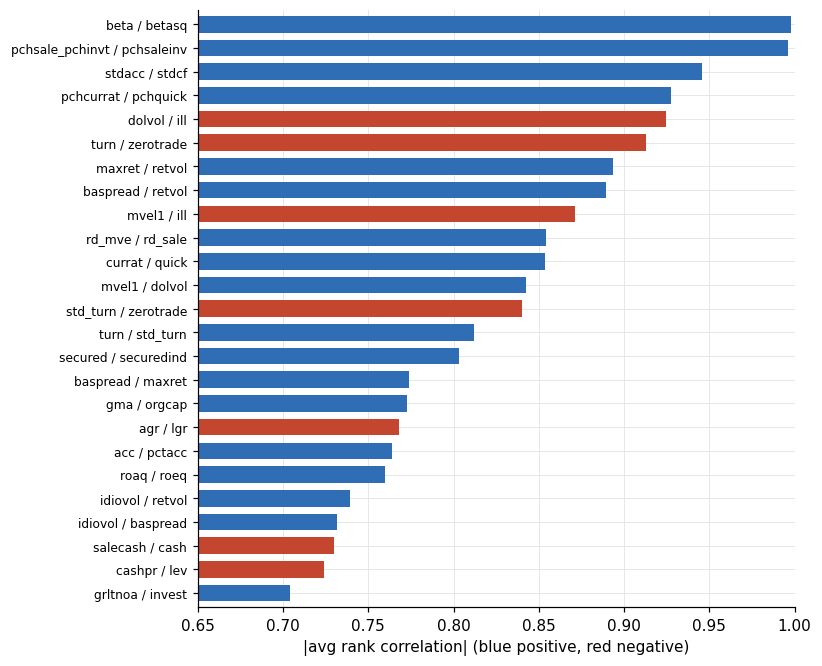

In [6]:
pairs = (pl.DataFrame({"pair": [f"{chars[i]} / {chars[j]}" for i, j in zip(*iu)], "rho": corr[iu]})
           .filter(pl.col("rho").abs() > 0.7).sort(pl.col("rho").abs()))
fig, ax = plt.subplots(figsize=(7, 0.25 * pairs.height + 0.8))
ax.barh(pairs["pair"], pairs["rho"].abs(), color=[BLUE if v > 0 else "#c4462f" for v in pairs["rho"]], height=0.7)
ax.set_xlim(0.65, 1); ax.set_xlabel("|avg rank correlation| (blue positive, red negative)")
ax.tick_params(axis="y", labelsize=8); ax.margins(y=0.01); plt.show()

## Selected pairs

In [7]:
ix = {c: i for i, c in enumerate(chars)}
sel = [("acc", "absacc"), ("acc", "pctacc"), ("ps", "ms"), ("ps", "nincr"), ("ms", "nincr"), ("ps", "roaq"),
       ("rd", "rd_mve"), ("rd_mve", "rd_sale"), ("secured", "securedind"), ("herf", "indmom"), ("mvel1", "mve_ia"),
       ("bm", "bm_ia"), ("cfp", "cfp_ia"), ("pchsaleinv", "saleinv"), ("pchsaleinv", "pchsale_pchinvt"), ("divi", "divo")]
pl.DataFrame([{"a": a, "b": b, "rho": corr[ix[a], ix[b]]} for a, b in sel])

a,b,rho
str,str,f64
"""acc""","""absacc""",-0.6912
"""acc""","""pctacc""",0.7638
"""ps""","""ms""",0.2752
"""ps""","""nincr""",-0.0089
"""ms""","""nincr""",0.0063
"""ps""","""roaq""",0.2826
"""rd""","""rd_mve""",0.2903
"""rd_mve""","""rd_sale""",0.8541
"""secured""","""securedind""",0.8033
